In [ ]:
!pip install -q lifelines scikit-survival ucimlrepo

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# Download the ACTG 175 dataset from UCI
aids = fetch_ucirepo(id=890)

# Predictor variables
X = aids.data.features

# Outcome variables
y = aids.data.targets

print("Predictor shape:", X.shape)
print("Outcome shape:", y.shape)

display(X.head())
display(y.head())

Predictor shape: (2139, 23)
Outcome shape: (2139, 1)


,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,...,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820
0,948,2,48,89.8128,0,0,0,100,0,0,...,0,0,1,0,1,0,422,477,566,324
1,1002,3,61,49.4424,0,0,0,90,0,1,...,0,1,3,0,1,0,162,218,392,564
2,961,3,45,88.4520,0,1,1,90,0,1,...,1,1,3,0,1,1,326,274,2063,1893
3,1166,3,47,85.2768,0,1,0,100,0,1,...,1,1,3,0,1,0,287,394,1590,966
4,1090,0,43,66.6792,0,1,0,100,0,1,...,1,1,3,0,0,0,504,353,870,782


,cid
0,0
1,1
2,0
3,0
4,0


In [ ]:
## Check how many patient has the end point observed(1) and how many was censored(0) and confirm if there is a missing value

print("All predictor columns:")
for column in X.columns:
    print(column)

print("\nMissing values:")
print(X.isnull().sum())

print("\nOutcome counts:")
print(y["cid"].value_counts())

print("\nPercentage:")
print(y["cid"].value_counts(normalize=True) * 100)


All predictor columns:
time
trt
age
wtkg
hemo
homo
drugs
karnof
oprior
z30
zprior
preanti
race
gender
str2
strat
symptom
treat
offtrt
cd40
cd420
cd80
cd820

Missing values:
time       0
trt        0
age        0
wtkg       0
hemo       0
homo       0
drugs      0
karnof     0
oprior     0
z30        0
zprior     0
preanti    0
race       0
gender     0
str2       0
strat      0
symptom    0
treat      0
offtrt     0
cd40       0
cd420      0
cd80       0
cd820      0
dtype: int64

Outcome counts:
cid
0    1618
1     521
Name: count, dtype: int64

Percentage:
cid
0    75.642824
1    24.357176
Name: proportion, dtype: float64


In [ ]:
!pip install lifelines

In [ ]:
from lifelines import KaplanMeierFitter

print("lifelines is working!")

lifelines is working!


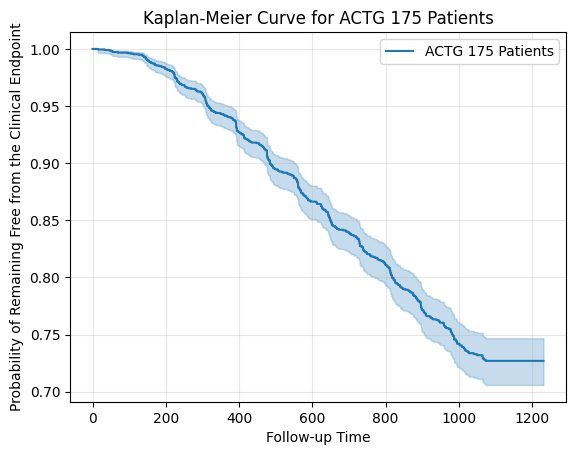

In [ ]:
## Kaplan-Meier curve: Helps to show the proportion of patients that have remained free from the clinical endpoint as time passes i.e
## the probability that the patient has not yet reach the end point

import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Combine time and outcome into one small dataframe
survival_data = pd.DataFrame({
    "time": X["time"],
    "cid": y["cid"]
})

# Create the Kaplan-Meier model
kmf = KaplanMeierFitter()

# Fit it to our data
kmf.fit(
    durations=survival_data["time"],
    event_observed=survival_data["cid"],
    label="ACTG 175 Patients"
)

# Plot the survival curve
kmf.plot_survival_function()

plt.title("Kaplan-Meier Curve for ACTG 175 Patients")
plt.xlabel("Follow-up Time")
plt.ylabel("Probability of Remaining Free from the Clinical Endpoint")
plt.grid(True, alpha=0.3)
plt.show()

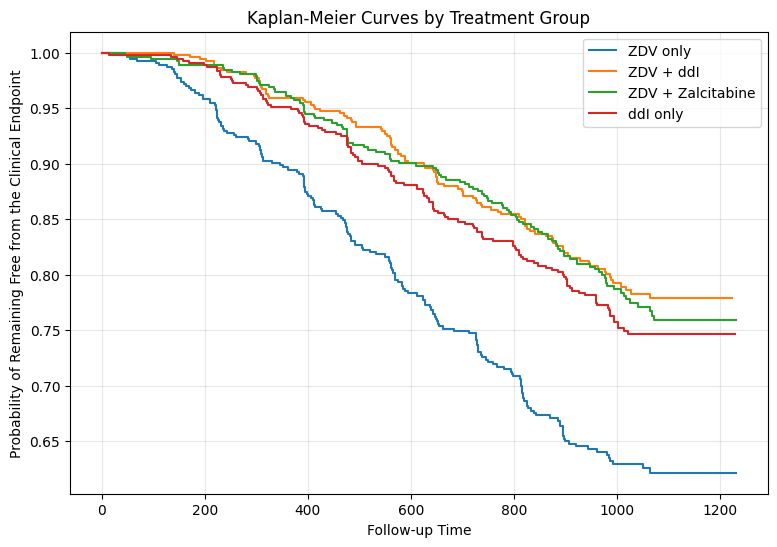

In [ ]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

treatment_names = {
    0: "ZDV only",
    1: "ZDV + ddI",
    2: "ZDV + Zalcitabine",
    3: "ddI only"
}

plt.figure(figsize=(9, 6))

for treatment, name in treatment_names.items():

    mask = X["trt"] == treatment

    kmf = KaplanMeierFitter()

    kmf.fit(
        durations=X.loc[mask, "time"],
        event_observed=y.loc[mask, "cid"],
        label=name
    )

    kmf.plot_survival_function(ci_show=False)

plt.title("Kaplan-Meier Curves by Treatment Group")
plt.xlabel("Follow-up Time")
plt.ylabel("Probability of Remaining Free from the Clinical Endpoint")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
import pandas as pd
# COX Model to check which of the variables/patient characteristics contributed most for the patient to reach the endpoint
# Baseline variables we want to test
baseline_variables = [
    "trt",
    "age",
    "wtkg",
    "hemo",
    "homo",
    "drugs",
    "karnof",
    "oprior",
    "z30",
    "zprior",
    "preanti",
    "race",
    "gender",
    "str2",
    "strat",
    "symptom",
    "cd40",
    "cd80"
]

# Create the Cox dataset
cox_data = X[["time"] + baseline_variables].copy()

# Add the endpoint indicator
cox_data["cid"] = y["cid"].values

print("Shape:", cox_data.shape)
display(cox_data.head())

Shape: (2139, 20)


,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,zprior,preanti,race,gender,str2,strat,symptom,cd40,cd80,cid
0,948,2,48,89.8128,0,0,0,100,0,0,1,0,0,0,0,1,0,422,566,0
1,1002,3,61,49.4424,0,0,0,90,0,1,1,895,0,0,1,3,0,162,392,1
2,961,3,45,88.4520,0,1,1,90,0,1,1,707,0,1,1,3,0,326,2063,0
3,1166,3,47,85.2768,0,1,0,100,0,1,1,1399,0,1,1,3,0,287,1590,0
4,1090,0,43,66.6792,0,1,0,100,0,1,1,1352,0,1,1,3,0,504,870,0


In [ ]:
clean_variables = [
    "trt",
    "age",
    "wtkg",
    "hemo",
    "homo",
    "drugs",
    "karnof",
    "oprior",
    "z30",
    "preanti",
    "race",
    "gender",
    "strat",
    "symptom",
    "cd40",
    "cd80"
]

cox_data_clean = X[["time"] + clean_variables].copy()
cox_data_clean["cid"] = y["cid"].values

print("Dataset shape:", cox_data_clean.shape)

Dataset shape: (2139, 18)


In [ ]:
# Encode categorical variables
cox_data_encoded = pd.get_dummies(
    cox_data_clean,
    columns=["trt", "strat"],
    drop_first=True,
    dtype=int
)

In [ ]:
from lifelines import CoxPHFitter

cox = CoxPHFitter()

cox.fit(
    cox_data_encoded,
    duration_col="time",
    event_col="cid"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 2139 total observations, 1618 right-censored observations>
             duration col = 'time'
                event col = 'cid'
      baseline estimation = breslow
   number of observations = 2139
number of events observed = 521
   partial log-likelihood = -3745.15
         time fit was run = 2026-11-01 02:49:36 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
age        0.01      1.01      0.01           -0.00            0.02                1.00                1.02
wtkg       0.00      1.00      0.00           -0.01            0.01                0.99                1.01
hemo      -0.02      0.98      0.22           -0.45            0.40                0.64                1.50
homo      -0.02      0.98      0.16           -0.34            0.29                0.71                1.34
drugs     -0.30      0.74      0.15           -0.60           -0.00                0.55                1.00
karnof    -0.02      0.98      0.01           -0.04           -0.01                0.96                0.99
oprior     0.11      1.11      0.28           -0.44            0.65                0.64                1.92
z30        0.21      1.24      0.23           -0.24            0.66                0.79                1.94
preanti    0.00      1.00      0.00            0.00            0.00                1.00                1.00
race      -0.07      0.93      0.11           -0.29            0.15                0.75                1.16
gender     0.03      1.03      0.19           -0.34            0.39                0.71                1.48
symptom    0.42      1.52      0.10            0.22            0.63                1.24                1.87
cd40      -0.00      1.00      0.00           -0.01           -0.00                0.99                1.00
cd80       0.00      1.00      0.00            0.00            0.00                1.00                1.00
trt_1     -0.80      0.45      0.12           -1.04           -0.56                0.35                0.57
trt_2     -0.66      0.52      0.12           -0.90           -0.42                0.41                0.66
trt_3     -0.58      0.56      0.12           -0.81           -0.35                0.45                0.70
strat_2    0.04      1.04      0.24           -0.43            0.52                0.65                1.68
strat_3   -0.20      0.82      0.27           -0.74            0.34                0.48                1.40

           cmp to     z      p  -log2(p)
covariate                               
age          0.00  1.15   0.25      1.99
wtkg         0.00  0.55   0.58      0.78
hemo         0.00 -0.09   0.92      0.11
homo         0.00 -0.14   0.88      0.18
drugs        0.00 -1.97   0.05      4.36
karnof       0.00 -3.56 <0.005     11.39
oprior       0.00  0.38   0.71      0.50
z30          0.00  0.93   0.35      1.50
preanti      0.00  2.90 <0.005      8.06
race         0.00 -0.65   0.51      0.96
gender       0.00  0.15   0.88      0.18
symptom      0.00  4.05 <0.005     14.26
cd40         0.00 -9.36 <0.005     66.79
cd80         0.00  5.26 <0.005     22.72
trt_1        0.00 -6.42 <0.005     32.80
trt_2        0.00 -5.39 <0.005     23.80
trt_3        0.00 -4.99 <0.005     20.63
strat_2      0.00  0.17   0.87      0.21
strat_3      0.00 -0.73   0.46      1.11
---
Concordance = 0.70
Partial AIC = 7528.30
log-likelihood ratio test = 241.11 on 19 df
-log2(p) of ll-ratio test = 131.92

In [ ]:
# Display hazard ratios and confidence intervals to 4 decimal places

cox_results = cox.summary

cox_results[[
    "exp(coef)",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "p"
]].loc[["cd40", "cd80", "preanti"]].round(4)

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
cd40,0.9958,0.9950,0.9967,0.0000
cd80,1.0004,1.0003,1.0006,0.0000
preanti,1.0005,1.0001,1.0008,0.0038


In [ ]:
%pip install --upgrade --force-reinstall scikit-learn scikit-survival

  Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached scikit_survival-0.28.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (7.0 kB)
  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached ecos-2.0.14-cp313-cp313-linux_x86_64.whl
  Using cached numexpr-2.14.2-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.0 kB)
  Using cached osqp-1.1.3-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (2.2 kB)
  Using cached pandas-3.1.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata 

In [ ]:
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv
from sklearn.model_selection import train_test_split
import pandas as pd

print("Everything imported successfully!")

Everything imported successfully!


In [ ]:
#create a clean variable to use as predictors
rsf_X = X[clean_variables].copy()

print("Predictor shape:", rsf_X.shape)
display(rsf_X.head())

Predictor shape: (2139, 16)


,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,gender,strat,symptom,cd40,cd80
0,2,48,89.8128,0,0,0,100,0,0,0,0,0,1,0,422,566
1,3,61,49.4424,0,0,0,90,0,1,895,0,0,3,0,162,392
2,3,45,88.4520,0,1,1,90,0,1,707,0,1,3,0,326,2063
3,3,47,85.2768,0,1,0,100,0,1,1399,0,1,3,0,287,1590
4,0,43,66.6792,0,1,0,100,0,1,1352,0,1,3,0,504,870


In [ ]:
rsf_X["trt"] = rsf_X["trt"].astype("category")
rsf_X["strat"] = rsf_X["strat"].astype("category")

rsf_X = pd.get_dummies(
    rsf_X,
    columns=["trt", "strat"],
    drop_first=True
)

print("Predictor shape after encoding:", rsf_X.shape)
display(rsf_X.head())

Predictor shape after encoding: (2139, 19)


,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,gender,symptom,cd40,cd80,trt_1,trt_2,trt_3,strat_2,strat_3
0,48,89.8128,0,0,0,100,0,0,0,0,0,0,422,566,False,True,False,False,False
1,61,49.4424,0,0,0,90,0,1,895,0,0,0,162,392,False,False,True,False,True
2,45,88.4520,0,1,1,90,0,1,707,0,1,0,326,2063,False,False,True,False,True
3,47,85.2768,0,1,0,100,0,1,1399,0,1,0,287,1590,False,False,True,False,True
4,43,66.6792,0,1,0,100,0,1,1352,0,1,0,504,870,False,False,False,False,True


In [ ]:
#Creating survivval outcome
rsf_y = Surv.from_arrays(
    event=y["cid"].astype(bool),
    time=X["time"]
)

print(rsf_y[:10])

[(False,  948.) ( True, 1002.) (False,  961.) (False, 1166.)
 (False, 1090.) (False, 1181.) ( True,  794.) (False,  957.)
 ( True,  198.) ( True,  188.)]


In [ ]:
# split into training and testing data.70% to train and 30% to test
X_train, X_test, y_train, y_test = train_test_split(
    rsf_X,
    rsf_y,
    test_size=0.30,
    random_state=42
)

print("Training patients:", X_train.shape[0])
print("Testing patients:", X_test.shape[0])

Training patients: 1497
Testing patients: 642


In [ ]:
# Training the random survival forest
from sksurv.ensemble import RandomSurvivalForest

rsf = RandomSurvivalForest(
    n_estimators=200,
    min_samples_split=10,
    min_samples_leaf=15,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42
)

rsf.fit(X_train, y_train)

print("Random Survival Forest training completed.")

Random Survival Forest training completed.


In [ ]:
#calculate the RSF C-index
rsf_cindex = rsf.score(X_test, y_test)

print("RSF Test C-index:", round(rsf_cindex, 6))

RSF Test C-index: 0.629547


In [ ]:
# Fixing COX on the same 70% training to compare with rsf
cox_full = rsf_X.copy()

cox_full["time"] = X["time"].values
cox_full["cid"] = y["cid"].values

display(cox_full.head())
print("Shape:", cox_full.shape)

,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,...,symptom,cd40,cd80,trt_1,trt_2,trt_3,strat_2,strat_3,time,cid
0,48,89.8128,0,0,0,100,0,0,0,0,...,0,422,566,False,True,False,False,False,948,0
1,61,49.4424,0,0,0,90,0,1,895,0,...,0,162,392,False,False,True,False,True,1002,1
2,45,88.4520,0,1,1,90,0,1,707,0,...,0,326,2063,False,False,True,False,True,961,0
3,47,85.2768,0,1,0,100,0,1,1399,0,...,0,287,1590,False,False,True,False,True,1166,0
4,43,66.6792,0,1,0,100,0,1,1352,0,...,0,504,870,False,False,False,False,True,1090,0


Shape: (2139, 21)


In [ ]:
# testing and training data using COX
cox_train = cox_full.loc[X_train.index]
cox_test = cox_full.loc[X_test.index]

print("Cox training patients:", len(cox_train))
print("Cox testing patients:", len(cox_test))

Cox training patients: 1497
Cox testing patients: 642


In [ ]:
from lifelines import CoxPHFitter

cox_fair = CoxPHFitter()

cox_fair.fit(
    cox_train,
    duration_col="time",
    event_col="cid"
)

print("Cox training completed.")

Cox training completed.


In [ ]:
# calculate the COX test C-index
cox_test_cindex = cox_fair.score(
    cox_test,
    scoring_method="concordance_index"
)

print("Cox Test C-index:", round(cox_test_cindex, 6))
print("RSF Test C-index:", round(rsf_cindex, 6))

Cox Test C-index: 0.668489
RSF Test C-index: 0.629547


In [ ]:

# Modifying the variables input using Z-score

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Make copies so we do not change our original data
X_train_z = X_train.copy()
X_test_z = X_test.copy()

# Create the Z-score scaler
scaler = StandardScaler()

# Fit the scaler ONLY on the training data
X_train_z[X_train.columns] = scaler.fit_transform(X_train)

# Use the same scaler on the test data
X_test_z[X_test.columns] = scaler.transform(X_test)

print("Original training data shape:", X_train.shape)
print("Z-score training data shape:", X_train_z.shape)

X_train_z.head()

Original training data shape: (1497, 19)
Z-score training data shape: (1497, 19)


,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,gender,symptom,cd40,cd80,trt_1,trt_2,trt_3,strat_2,strat_3
816,0.352701,0.010032,-0.300522,0.718831,-0.372026,-0.919514,-0.140552,0.896445,-0.571971,-0.642078,0.470153,-0.445599,-0.944094,-0.798757,-0.581207,1.786974,-0.594581,2.112701,-0.824703
187,0.236531,-0.752430,-0.300522,0.718831,-0.372026,0.777789,-0.140552,0.896445,0.114473,1.557443,0.470153,-0.445599,-0.303482,1.237993,1.720557,-0.559605,-0.594581,-0.473328,1.212558
619,2.676101,-0.479010,-0.300522,-1.391148,-0.372026,-0.919514,-0.140552,0.896445,1.590856,-0.642078,-2.126966,-0.445599,-0.876661,-0.651290,1.720557,-0.559605,-0.594581,-0.473328,1.212558
1855,0.585041,0.158971,-0.300522,0.718831,-0.372026,0.777789,-0.140552,-1.115517,-0.821204,1.557443,0.470153,-0.445599,-0.362485,0.955883,-0.581207,-0.559605,1.681857,-0.473328,-0.824703
158,-0.925170,1.231452,-0.300522,0.718831,-0.372026,0.777789,-0.140552,-1.115517,-0.498047,-0.642078,0.470153,-0.445599,-1.028385,-0.273006,-0.581207,-0.559605,1.681857,2.112701,-0.824703


In [ ]:
# Running the RSF on the modified dataset

from sksurv.ensemble import RandomSurvivalForest

rsf_z = RandomSurvivalForest(
    n_estimators=200,
    min_samples_split=10,
    min_samples_leaf=15,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42
)

rsf_z.fit(X_train_z, y_train)

zscore_cindex = rsf_z.score(X_test_z, y_test)

print("Original RSF Test C-index:", round(rsf_cindex, 6))
print("Z-score RSF Test C-index:", round(zscore_cindex, 6))

Original RSF Test C-index: 0.629547
Z-score RSF Test C-index: 0.629559


In [ ]:
# Continuous variables that may be candidates for log transformation
continuous_vars = [
    "age", "wtkg", "karnof", "preanti", "cd40", "cd80"
]

# Check their skewness in the TRAINING data only
skewness = X_train[continuous_vars].skew().sort_values(
    key=abs,
    ascending=False
)

print("Skewness of continuous variables:")
print(skewness)

Skewness of continuous variables:
cd80       1.360030
preanti    1.161621
karnof    -1.025239
cd40       0.761392
wtkg       0.687683
age        0.580196
dtype: float64


In [ ]:
import numpy as np

# Start again from the ORIGINAL data to make the data less skewed
X_train_log = X_train.copy()
X_test_log = X_test.copy()

# Only variables where log transformation reduced skewness
log_vars = ["preanti", "cd80"]

for col in log_vars:
    X_train_log[col] = np.log1p(X_train_log[col])
    X_test_log[col] = np.log1p(X_test_log[col])

# Check the final skewness
comparison = pd.DataFrame({
    "Original": X_train[log_vars].skew(),
    "After_Log": X_train_log[log_vars].skew()
})

print(comparison)

         Original  After_Log
preanti  1.161621  -0.206360
cd80     1.360030  -0.395564


In [ ]:
from sksurv.ensemble import RandomSurvivalForest

rsf_log = RandomSurvivalForest(
    n_estimators=200,
    min_samples_split=10,
    min_samples_leaf=15,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42
)

# Train using log-transformed predictors
rsf_log.fit(X_train_log, y_train)

# Test on the log-transformed test data
log_cindex = rsf_log.score(X_test_log, y_test)
print("Original RSF Test C-index:", round(rsf_cindex, 6))
print("Z-score RSF Test C-index:", round(zscore_cindex, 6))
print("Log-transformed RSF Test C-index:", round(log_cindex, 6))

Original RSF Test C-index: 0.629547
Z-score RSF Test C-index: 0.629559
Log-transformed RSF Test C-index: 0.629496


In [ ]:
import pandas as pd

# Use the already encoded training and testing datasets
X_train_cox = X_train.copy()
X_test_cox = X_test.copy()

# Check the datasets
print("Training shape:", X_train_cox.shape)
print("Testing shape:", X_test_cox.shape)
print("Columns:", X_train_cox.columns.tolist())

Training shape: (1497, 19)
Testing shape: (642, 19)
Columns: ['age', 'wtkg', 'hemo', 'homo', 'drugs', 'karnof', 'oprior', 'z30', 'preanti', 'race', 'gender', 'symptom', 'cd40', 'cd80', 'trt_1', 'trt_2', 'trt_3', 'strat_2', 'strat_3']


In [ ]:
# Apply Z-Score starndardization
from sklearn.preprocessing import StandardScaler

# Continuous variables to standardize
continuous_vars = [
    "age", "wtkg", "karnof",
    "preanti", "cd40", "cd80"
]

# Copy the correctly encoded datasets
X_train_cox_z = X_train_cox.copy()
X_test_cox_z = X_test_cox.copy()

# Fit the scaler using training data only
scaler_cox = StandardScaler()

X_train_cox_z[continuous_vars] = scaler_cox.fit_transform(
    X_train_cox[continuous_vars]
)

X_test_cox_z[continuous_vars] = scaler_cox.transform(
    X_test_cox[continuous_vars]
)

print("Z-score training shape:", X_train_cox_z.shape)
print("Z-score testing shape:", X_test_cox_z.shape)
print("\nStandardized variable means:")
print(X_train_cox_z[continuous_vars].mean().round(3))

Z-score training shape: (1497, 19)
Z-score testing shape: (642, 19)

Standardized variable means:
age       -0.0
wtkg       0.0
karnof    -0.0
preanti   -0.0
cd40       0.0
cd80       0.0
dtype: float64


In [ ]:
# Train the Cox model using Z-score standardized inputs

from lifelines import CoxPHFitter

# Prepare training data
cox_train_z = X_train_cox_z.copy()
cox_train_z["time"] = X.loc[X_train_cox_z.index, "time"]
cox_train_z["cid"] = y.loc[X_train_cox_z.index, "cid"]

# Prepare testing data
cox_test_z = X_test_cox_z.copy()
cox_test_z["time"] = X.loc[X_test_cox_z.index, "time"]
cox_test_z["cid"] = y.loc[X_test_cox_z.index, "cid"]

# Train the Cox model
cox_z = CoxPHFitter()
cox_z.fit(
    cox_train_z,
    duration_col="time",
    event_col="cid"
)

# Calculate test C-index
cox_z_cindex = cox_z.score(
    cox_test_z,
    scoring_method="concordance_index"
)

print("Cox with Z-score C-index:", round(cox_z_cindex, 6))

Cox with Z-score C-index: 0.668489


In [ ]:
#Apply log transformation to the Cox inputs

import numpy as np

# Copy the original, correctly encoded datasets
X_train_cox_log = X_train_cox.copy()
X_test_cox_log = X_test_cox.copy()

# Variables selected for log transformation
log_vars = ["preanti", "cd80"]

# Apply log transformation
for col in log_vars:
    X_train_cox_log[col] = np.log1p(X_train_cox_log[col])
    X_test_cox_log[col] = np.log1p(X_test_cox_log[col])

print("Log-transformed training shape:", X_train_cox_log.shape)
print("Log-transformed testing shape:", X_test_cox_log.shape)

print("\nSkewness after transformation:")
print(X_train_cox_log[log_vars].skew().round(3))

Log-transformed training shape: (1497, 19)
Log-transformed testing shape: (642, 19)

Skewness after transformation:
preanti   -0.206
cd80      -0.396
dtype: float64


In [ ]:
# Train the Cox model with log-transformed inputs
from lifelines import CoxPHFitter

# Prepare training data
cox_train_log = X_train_cox_log.copy()
cox_train_log["time"] = X.loc[X_train_cox_log.index, "time"]
cox_train_log["cid"] = y.loc[X_train_cox_log.index, "cid"]

# Prepare testing data
cox_test_log = X_test_cox_log.copy()
cox_test_log["time"] = X.loc[X_test_cox_log.index, "time"]
cox_test_log["cid"] = y.loc[X_test_cox_log.index, "cid"]

# Train the Cox model
cox_log = CoxPHFitter()
cox_log.fit(
    cox_train_log,
    duration_col="time",
    event_col="cid"
)

# Calculate test C-index
cox_log_cindex = cox_log.score(
    cox_test_log,
    scoring_method="concordance_index"
)

print("Cox with log transformation C-index:",
      round(cox_log_cindex, 6))

Cox with log transformation C-index: 0.670375


In [ ]:
from lifelines import CoxPHFitter

# Prepare original training data
cox_train_original = X_train_cox.copy()
cox_train_original["time"] = X.loc[X_train_cox.index, "time"]
cox_train_original["cid"] = y.loc[X_train_cox.index, "cid"]

# Prepare original testing data
cox_test_original = X_test_cox.copy()
cox_test_original["time"] = X.loc[X_test_cox.index, "time"]
cox_test_original["cid"] = y.loc[X_test_cox.index, "cid"]

# Train original Cox model
cox_original = CoxPHFitter()
cox_original.fit(
    cox_train_original,
    duration_col="time",
    event_col="cid"
)

# Evaluate on test data
cox_original_cindex = cox_original.score(
    cox_test_original,
    scoring_method="concordance_index"
)

print("Cox original C-index:", round(cox_original_cindex, 6))
print("Cox Z-score C-index:", round(cox_z_cindex, 6))
print("Cox log C-index:", round(cox_log_cindex, 6))

Cox original C-index: 0.668489
Cox Z-score C-index: 0.668489
Cox log C-index: 0.670375


In [ ]:
# Five fold crowss validation.the same five fold will be used for COX PH and RSF
#using stratified folds to keep the proportion of patients who experienced the clinical endpoint reasonably similar across folds.
from sklearn.model_selection import StratifiedKFold

# Combine the original training and testing patient indices
all_indices = X_train.index.append(X_test.index)

# Get event status for each patient
event_status = y.loc[all_indices, "cid"]

# Create five reproducible folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(all_indices, event_status))

print("Total patients:", len(all_indices))
print("Number of folds:", len(folds))

for i, (train_idx, test_idx) in enumerate(folds, start=1):
    print(
        f"Fold {i}: "
        f"{len(train_idx)} training, "
        f"{len(test_idx)} testing"
    )



Total patients: 2139
Number of folds: 5
Fold 1: 1711 training, 428 testing
Fold 2: 1711 training, 428 testing
Fold 3: 1711 training, 428 testing
Fold 4: 1711 training, 428 testing
Fold 5: 1712 training, 427 testing


In [ ]:
#: Prepare the dataset for cross-validation
import pandas as pd

# Combine original training and testing predictors
X_cv = pd.concat([X_train, X_test]).copy()

# Encode categorical variables
# Variables are already encoded
X_cv = X_cv.copy()

# Arrange patients in the same order as the folds
X_cv = X_cv.loc[all_indices]

# Prepare survival outcomes
y_cv = pd.DataFrame(index=all_indices)

y_cv["time"] = X.loc[all_indices, "time"]
y_cv["cid"] = y.loc[all_indices, "cid"]

# Check the results
print("Predictor shape:", X_cv.shape)
print("Outcome shape:", y_cv.shape)
print("Number of events:", y_cv["cid"].sum())
print("Missing values:", X_cv.isna().sum().sum())
print("Predictor shape:", X_cv.shape)
print("Outcome shape:", y_cv.shape)
print("Number of events:", y_cv["cid"].sum())
print("Missing values:", X_cv.isna().sum().sum())

Predictor shape: (2139, 19)
Outcome shape: (2139, 2)
Number of events: 521
Missing values: 0
Predictor shape: (2139, 19)
Outcome shape: (2139, 2)
Number of events: 521
Missing values: 0


In [ ]:
#Five-fold cross-validation for the original Cox model
from lifelines import CoxPHFitter
import numpy as np

cox_cv_scores = []

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    # Select training and testing patients
    train_data = X_cv.iloc[train_idx].copy()
    test_data = X_cv.iloc[test_idx].copy()

    # Add survival outcomes using row positions
    train_data["time"] = y_cv["time"].iloc[train_idx].to_numpy()
    train_data["cid"] = y_cv["cid"].iloc[train_idx].to_numpy()

    test_data["time"] = y_cv["time"].iloc[test_idx].to_numpy()
    test_data["cid"] = y_cv["cid"].iloc[test_idx].to_numpy()

    # Train Cox model
    cox_model = CoxPHFitter()
    cox_model.fit(
        train_data,
        duration_col="time",
        event_col="cid"
    )

    # Evaluate model
    cindex = cox_model.score(
        test_data,
        scoring_method="concordance_index"
    )

    cox_cv_scores.append(cindex)

    print(f"Fold {fold_number}: C-index = {cindex:.4f}")

print("\nMean C-index:", round(np.mean(cox_cv_scores), 4))
print("Standard deviation:", round(np.std(cox_cv_scores), 4))

Fold 1: C-index = 0.6955
Fold 2: C-index = 0.6617
Fold 3: C-index = 0.6985
Fold 4: C-index = 0.6897
Fold 5: C-index = 0.6654

Mean C-index: 0.6822
Standard deviation: 0.0155


In [ ]:
#Five-fold cross-validation for Z-score Cox PH
from sklearn.preprocessing import StandardScaler
from lifelines import CoxPHFitter
import numpy as np

cox_z_cv_scores = []

continuous_vars = [
    "age", "wtkg", "karnof",
    "preanti", "cd40", "cd80"
]

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    # Select training and testing data
    X_tr = X_cv.iloc[train_idx].copy()
    X_te = X_cv.iloc[test_idx].copy()

    # Standardize continuous variables
    scaler = StandardScaler()

    X_tr[continuous_vars] = scaler.fit_transform(
        X_tr[continuous_vars]
    )

    X_te[continuous_vars] = scaler.transform(
        X_te[continuous_vars]
    )

    # Add survival outcomes
    X_tr["time"] = y_cv["time"].iloc[train_idx].to_numpy()
    X_tr["cid"] = y_cv["cid"].iloc[train_idx].to_numpy()

    X_te["time"] = y_cv["time"].iloc[test_idx].to_numpy()
    X_te["cid"] = y_cv["cid"].iloc[test_idx].to_numpy()

    # Train Cox model
    model = CoxPHFitter()
    model.fit(X_tr, duration_col="time", event_col="cid")

    # Evaluate
    cindex = model.score(
        X_te,
        scoring_method="concordance_index"
    )

    cox_z_cv_scores.append(cindex)

    print(f"Fold {fold_number}: C-index = {cindex:.4f}")

print("\nMean C-index:", round(np.mean(cox_z_cv_scores), 4))
print("Standard deviation:", round(np.std(cox_z_cv_scores), 4))

Fold 1: C-index = 0.6955
Fold 2: C-index = 0.6617
Fold 3: C-index = 0.6985
Fold 4: C-index = 0.6897
Fold 5: C-index = 0.6654

Mean C-index: 0.6822
Standard deviation: 0.0155


In [ ]:
import numpy as np
from lifelines import CoxPHFitter

cox_log_cv_scores = []

log_vars = ["preanti", "cd80"]

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    # Select training and testing data
    X_tr = X_cv.iloc[train_idx].copy()
    X_te = X_cv.iloc[test_idx].copy()

    # Apply log transformation
    for col in log_vars:
        X_tr[col] = np.log1p(X_tr[col])
        X_te[col] = np.log1p(X_te[col])

    # Add survival outcomes
    X_tr["time"] = y_cv["time"].iloc[train_idx].to_numpy()
    X_tr["cid"] = y_cv["cid"].iloc[train_idx].to_numpy()

    X_te["time"] = y_cv["time"].iloc[test_idx].to_numpy()
    X_te["cid"] = y_cv["cid"].iloc[test_idx].to_numpy()

    # Train Cox model
    model = CoxPHFitter()
    model.fit(
        X_tr,
        duration_col="time",
        event_col="cid"
    )

    # Calculate test C-index
    cindex = model.score(
        X_te,
        scoring_method="concordance_index"
    )

    cox_log_cv_scores.append(cindex)

    print(f"Fold {fold_number}: C-index = {cindex:.4f}")

print("\nMean C-index:", round(np.mean(cox_log_cv_scores), 4))
print("Standard deviation:", round(np.std(cox_log_cv_scores), 4))

Fold 1: C-index = 0.6967
Fold 2: C-index = 0.6591
Fold 3: C-index = 0.6944
Fold 4: C-index = 0.6942
Fold 5: C-index = 0.6601

Mean C-index: 0.6809
Standard deviation: 0.0174


In [ ]:
#Five-fold cross-validation for the original RSF

from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv
import numpy as np

# Convert outcomes to survival format
y_surv_cv = Surv.from_arrays(
    event=y_cv["cid"].astype(bool).to_numpy(),
    time=y_cv["time"].to_numpy()
)

rsf_cv_scores = []

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    # Select training and testing patients
    X_tr = X_cv.iloc[train_idx]
    X_te = X_cv.iloc[test_idx]

    y_tr = y_surv_cv[train_idx]
    y_te = y_surv_cv[test_idx]

    # Train Random Survival Forest
    rsf_model = RandomSurvivalForest(
        n_estimators=200,
        min_samples_split=10,
        min_samples_leaf=15,
        random_state=42,
        n_jobs=-1
    )

    rsf_model.fit(X_tr, y_tr)

    # Evaluate on testing fold
    cindex = rsf_model.score(X_te, y_te)

    rsf_cv_scores.append(cindex)

    print(f"Fold {fold_number}: C-index = {cindex:.4f}")

print("\nMean C-index:", round(np.mean(rsf_cv_scores), 4))
print("Standard deviation:", round(np.std(rsf_cv_scores), 4))

Fold 1: C-index = 0.6747
Fold 2: C-index = 0.6474
Fold 3: C-index = 0.6559
Fold 4: C-index = 0.6584
Fold 5: C-index = 0.6026

Mean C-index: 0.6478
Standard deviation: 0.0243


In [ ]:
#Five-fold cross-validation for Z-score RSF
from sklearn.preprocessing import StandardScaler
from sksurv.ensemble import RandomSurvivalForest
import numpy as np

rsf_z_cv_scores = []

continuous_vars = [
    "age", "wtkg", "karnof",
    "preanti", "cd40", "cd80"
]

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    # Select training and testing data
    X_tr = X_cv.iloc[train_idx].copy()
    X_te = X_cv.iloc[test_idx].copy()

    # Fit scaler on training data only
    scaler = StandardScaler()

    X_tr[continuous_vars] = scaler.fit_transform(
        X_tr[continuous_vars]
    )

    X_te[continuous_vars] = scaler.transform(
        X_te[continuous_vars]
    )

    # Survival outcomes
    y_tr = y_surv_cv[train_idx]
    y_te = y_surv_cv[test_idx]

    # Train RSF
    rsf_model = RandomSurvivalForest(
        n_estimators=200,
        min_samples_split=10,
        min_samples_leaf=15,
        random_state=42,
        n_jobs=-1
    )

    rsf_model.fit(X_tr, y_tr)

    # Evaluate model
    cindex = rsf_model.score(X_te, y_te)

    rsf_z_cv_scores.append(cindex)

    print(f"Fold {fold_number}: C-index = {cindex:.4f}")

print("\nMean C-index:", round(np.mean(rsf_z_cv_scores), 4))
print("Standard deviation:", round(np.std(rsf_z_cv_scores), 4))

Fold 1: C-index = 0.6742
Fold 2: C-index = 0.6474
Fold 3: C-index = 0.6560
Fold 4: C-index = 0.6581
Fold 5: C-index = 0.6029

Mean C-index: 0.6477
Standard deviation: 0.024


In [ ]:
#Five-fold cross-validation for log-transformed RSF
import numpy as np
from sksurv.ensemble import RandomSurvivalForest

rsf_log_cv_scores = []

log_vars = ["preanti", "cd80"]

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    # Select training and testing patients
    X_tr = X_cv.iloc[train_idx].copy()
    X_te = X_cv.iloc[test_idx].copy()

    # Apply log transformation
    for col in log_vars:
        X_tr[col] = np.log1p(X_tr[col])
        X_te[col] = np.log1p(X_te[col])

    # Select survival outcomes
    y_tr = y_surv_cv[train_idx]
    y_te = y_surv_cv[test_idx]

    # Train RSF
    rsf_model = RandomSurvivalForest(
        n_estimators=200,
        min_samples_split=10,
        min_samples_leaf=15,
        random_state=42,
        n_jobs=-1
    )

    rsf_model.fit(X_tr, y_tr)

    # Evaluate on testing fold
    cindex = rsf_model.score(X_te, y_te)

    rsf_log_cv_scores.append(cindex)

    print(f"Fold {fold_number}: C-index = {cindex:.4f}")

print("\nMean C-index:", round(np.mean(rsf_log_cv_scores), 4))
print("Standard deviation:", round(np.std(rsf_log_cv_scores), 4))

Fold 1: C-index = 0.6744
Fold 2: C-index = 0.6474
Fold 3: C-index = 0.6564
Fold 4: C-index = 0.6583
Fold 5: C-index = 0.6030

Mean C-index: 0.6479
Standard deviation: 0.0241


In [ ]:
#Train the original RSF for variable importance
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

# Prepare the original encoded training and testing data
X_rsf_train = X_train_cox.copy()
X_rsf_test = X_test_cox.copy()

# Prepare survival outcomes
y_rsf_train = Surv.from_arrays(
    event=y.loc[X_rsf_train.index, "cid"].astype(bool),
    time=X.loc[X_rsf_train.index, "time"]
)

y_rsf_test = Surv.from_arrays(
    event=y.loc[X_rsf_test.index, "cid"].astype(bool),
    time=X.loc[X_rsf_test.index, "time"]
)

# Train RSF
rsf_importance_model = RandomSurvivalForest(
    n_estimators=200,
    min_samples_split=10,
    min_samples_leaf=15,
    random_state=42,
    n_jobs=-1
)

rsf_importance_model.fit(X_rsf_train, y_rsf_train)

print("RSF model trained successfully!")
print("Test C-index:",
      round(rsf_importance_model.score(X_rsf_test, y_rsf_test), 4))

RSF model trained successfully!
Test C-index: 0.6295


In [ ]:
#Calculate RSF variable importance
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate variable importance
result = permutation_importance(
    rsf_importance_model,
    X_rsf_test,
    y_rsf_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create importance table
importance_df = pd.DataFrame({
    "Variable": X_rsf_test.columns,
    "Importance": result.importances_mean,
    "Std": result.importances_std
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.round(4).to_string(index=False))

Variable  Importance    Std
    cd40      0.0683 0.0100
   trt_1      0.0083 0.0035
 symptom      0.0081 0.0068
   trt_2      0.0081 0.0038
   trt_3      0.0037 0.0016
    cd80      0.0037 0.0091
     z30      0.0034 0.0023
 preanti      0.0033 0.0044
  karnof      0.0028 0.0073
    wtkg      0.0023 0.0035
    homo      0.0011 0.0011
 strat_3      0.0008 0.0027
    hemo      0.0006 0.0007
   drugs      0.0006 0.0006
     age     -0.0000 0.0021
 strat_2     -0.0002 0.0006
  oprior     -0.0002 0.0006
    race     -0.0008 0.0017
  gender     -0.0010 0.0012


In [ ]:

# Extract Cox hazard ratios and statistical results
cox_results = cox_original.summary[
    ["exp(coef)", "exp(coef) lower 95%",
     "exp(coef) upper 95%", "p"]
].copy()

# Rename columns for easier interpretation
cox_results.columns = [
    "Hazard Ratio",
    "Lower 95% CI",
    "Upper 95% CI",
    "P-value"
]

# Sort by statistical significance
cox_results = cox_results.sort_values("P-value")

print(cox_results.round(4).to_string())

           Hazard Ratio  Lower 95% CI  Upper 95% CI  P-value
covariate                                                   
cd40             0.9953        0.9943        0.9964   0.0000
trt_1            0.4535        0.3383        0.6079   0.0000
cd80             1.0005        1.0003        1.0007   0.0000
trt_2            0.5370        0.4025        0.7165   0.0000
trt_3            0.5837        0.4442        0.7671   0.0001
karnof           0.9692        0.9537        0.9850   0.0001
symptom          1.5990        1.2526        2.0413   0.0002
preanti          1.0003        0.9999        1.0007   0.0895
oprior           1.7668        0.9075        3.4397   0.0941
drugs            0.8003        0.5523        1.1596   0.2390
race             0.8606        0.6565        1.1281   0.2768
gender           1.2510        0.8045        1.9453   0.3201
homo             0.8729        0.5930        1.2849   0.4907
z30              1.1689        0.6798        2.0099   0.5725
age              1.0030 